# Segmentación de inundaciones con U-Net — versión mejorada

Copia del notebook `1. flood_segmentation.ipynb` con las mejoras de la práctica AA3. El original se mantiene sin cambios para poder comparar.

**Qué cambia respecto al original**

| # | Cambio | Motivo |
|---|--------|--------|
| 1 | División **entrenamiento / test** (80/20, semilla fija) | Punto 4 del enunciado; el original entrenaba y evaluaba con las mismas imágenes |
| 2 | Pérdida e IoU calculados **en entrenamiento y en test** en cada época | Apartados b) y c) de la entrega |
| 3 | **Data augmentation** con `transforms.v2.Compose`, aplicada a la vez a imagen y máscara | Aportación propuesta en clase; solo hay 290 imágenes |
| 4 | **Scheduler corregido** (lr 0.001, se reduce a la mitad cada 10 épocas, 40 épocas) | En el original el lr se dividía entre 2 en cada época y el modelo dejaba de aprender en la época ~6 |
| 5 | Resolución **128×128** (múltiplo de 16) en lugar de 100×100 | Más detalle en los bordes y sin padding en la U-Net |
| 6 | Umbral de máscara `> 127` y redimensionado de máscara con vecino más cercano | Las máscaras tienen píxeles grises en los bordes; `> 0` los marcaba como agua |
| 7 | Métricas globales: IoU inundación, IoU fondo, mIoU, Dice y exactitud por píxel | La exactitud sola engaña; el IoU se acumula sobre todo el conjunto, no por lote |
| 8 | Figura de **evolución de la predicción** por épocas | Ver cómo la máscara predicha converge |
| 9 | **Análisis de errores** (mejores y peores imágenes de test) | Comprobar dónde falla (cielo, horizonte, reflejos) |
| 10 | Comparación con **K-means y Chan-Vese** (métodos clásicos de la unidad 3) | Justificar con números la ventaja de la U-Net |
| 11 | **Ablación**: el efecto de cada mejora por separado, incluida *bilinear* frente a convolución transpuesta | Medir qué aporta cada cambio |

Todos los resultados se guardan en `resultados_unet_mejorado/` para no pisar los del original.

## 1. Importación de librerías

Además de las del original se usan `torchvision.transforms.v2` y `tv_tensors` para el augmentation conjunto de imagen y máscara (requiere **torchvision ≥ 0.16**), y `scikit-learn` / `scikit-image` para los métodos clásicos.

In [1]:
import os
import json
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import PIL.Image
import torch
import torch.nn.functional as F
import torchvision
from torchvision.transforms import v2
from torchvision import tv_tensors
from matplotlib import pyplot as plt
from torch.optim.lr_scheduler import StepLR
from sklearn.cluster import KMeans
from skimage.color import rgb2gray
from skimage.segmentation import chan_vese

print('torch', torch.__version__, '| torchvision', torchvision.__version__)

torch 2.14.0+cu130 | torchvision 0.29.0+cpu


## 2. Configuración general

Igual que en el original, todos los parámetros se definen al principio y se guardan en un JSON. `CONFIG_BASE` es la configuración del modelo mejorado; la sección de ablación crea variaciones a partir de ella.

- `EJECUTAR_METODOS_CLASICOS`: compara con K-means y Chan-Vese (unos minutos en CPU).
- `EJECUTAR_ABLACION`: entrena 4 modelos más para medir cada mejora por separado (es la parte más larga).

In [2]:
# Rutas de entrada
RUTA_IMAGENES = Path('./data/Image')
RUTA_MASCARAS = Path('./data/Mask')

# Carpeta de salida (distinta a la del notebook original)
RUTA_RESULTADOS = Path('./resultados_unet_mejorado')
RUTA_FIGURAS = RUTA_RESULTADOS / 'figuras'
RUTA_MODELOS = RUTA_RESULTADOS / 'modelos'
for carpeta in [RUTA_RESULTADOS, RUTA_FIGURAS, RUTA_MODELOS]:
    carpeta.mkdir(parents=True, exist_ok=True)

# Configuración del modelo mejorado
CONFIG_BASE = {
    'tamanio_imagen': 128,       # múltiplo de 16: la U-Net reduce 4 veces a la mitad
    'batch_size': 16,
    'epochs': 40,
    'learning_rate': 0.001,
    'step_size_scheduler': 10,   # cada 10 épocas...
    'gamma_scheduler': 0.5,      # ...el lr se reduce a la mitad
    'augmentation': True,
    'bilinear': False,           # False = convolución transpuesta (aprende el upsampling)
    'proporcion_test': 0.2,
    'umbral_mascara': 127,       # píxel de máscara > 127 -> inundado
    'semilla': 42,
}

EJECUTAR_METODOS_CLASICOS = True
EJECUTAR_ABLACION = True

# Selección de dispositivo
USAR_GPU = True
USAR_MPS = False
if USAR_GPU and torch.cuda.is_available():
    device = torch.device('cuda')
elif USAR_MPS and torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')
print(f'Dispositivo seleccionado: {device}')


def fijar_semilla(semilla):
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(semilla)


fijar_semilla(CONFIG_BASE['semilla'])

with open(RUTA_RESULTADOS / 'configuracion.json', 'w', encoding='utf-8') as f:
    json.dump({**CONFIG_BASE, 'device': str(device)}, f, indent=4, ensure_ascii=False)
CONFIG_BASE

Dispositivo seleccionado: cuda


{'tamanio_imagen': 128,
 'batch_size': 16,
 'epochs': 40,
 'learning_rate': 0.001,
 'step_size_scheduler': 10,
 'gamma_scheduler': 0.5,
 'augmentation': True,
 'bilinear': False,
 'proporcion_test': 0.2,
 'umbral_mascara': 127,
 'semilla': 42}

## 3. Bloques de la U-Net

La arquitectura es la misma que en el original (encoder, decoder y skip connections). Se mantiene sin cambios para que las diferencias de resultados se deban solo a los datos y al entrenamiento.

In [3]:
class DoubleConv(torch.nn.Module):
    # (Conv 3x3 -> BatchNorm -> ReLU) x 2

    def __init__(self, in_channels, out_channels, mid_channels=None):
        super().__init__()
        if not mid_channels:
            mid_channels = out_channels
        self.double_conv = torch.nn.Sequential(
            torch.nn.Conv2d(in_channels, mid_channels, kernel_size=3, padding=1, bias=False),
            torch.nn.BatchNorm2d(mid_channels),
            torch.nn.ReLU(inplace=True),
            torch.nn.Conv2d(mid_channels, out_channels, kernel_size=3, padding=1, bias=False),
            torch.nn.BatchNorm2d(out_channels),
            torch.nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.double_conv(x)


class Down(torch.nn.Module):
    # Encoder: MaxPool (reduce la resolución a la mitad) + doble convolución

    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.maxpool_conv = torch.nn.Sequential(
            torch.nn.MaxPool2d(2),
            DoubleConv(in_channels, out_channels),
        )

    def forward(self, x):
        return self.maxpool_conv(x)


class Up(torch.nn.Module):
    # Decoder: aumenta la resolución, concatena la skip connection y aplica doble convolución

    def __init__(self, in_channels, out_channels, bilinear=True):
        super().__init__()
        if bilinear:
            # Interpolación fija: no aprende pesos
            self.up = torch.nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
            self.conv = DoubleConv(in_channels, out_channels, in_channels // 2)
        else:
            # Convolución transpuesta: aprende cómo expandir
            self.up = torch.nn.ConvTranspose2d(in_channels, in_channels // 2, kernel_size=2, stride=2)
            self.conv = DoubleConv(in_channels, out_channels)

    def forward(self, x1, x2):
        x1 = self.up(x1)
        # Ajuste por diferencias de tamaño debidas a redondeos (con 128x128 no hace falta)
        diffY = x2.size()[2] - x1.size()[2]
        diffX = x2.size()[3] - x1.size()[3]
        x1 = F.pad(x1, [diffX // 2, diffX - diffX // 2, diffY // 2, diffY - diffY // 2])
        x = torch.cat([x2, x1], dim=1)  # skip connection: recupera el "dónde"
        return self.conv(x)


class OutConv(torch.nn.Module):
    # Convolución 1x1 que convierte las características en logits de cada clase

    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = torch.nn.Conv2d(in_channels, out_channels, kernel_size=1)

    def forward(self, x):
        return self.conv(x)


class UNet(torch.nn.Module):
    def __init__(self, n_channels, n_classes, bilinear=False):
        super().__init__()
        self.n_channels = n_channels
        self.n_classes = n_classes
        self.bilinear = bilinear

        # Encoder
        self.inc = DoubleConv(n_channels, 64)
        self.down1 = Down(64, 128)
        self.down2 = Down(128, 256)
        self.down3 = Down(256, 512)
        factor = 2 if bilinear else 1
        self.down4 = Down(512, 1024 // factor)

        # Decoder
        self.up1 = Up(1024, 512 // factor, bilinear)
        self.up2 = Up(512, 256 // factor, bilinear)
        self.up3 = Up(256, 128 // factor, bilinear)
        self.up4 = Up(128, 64, bilinear)
        self.outc = OutConv(64, n_classes)

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)
        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)
        return self.outc(x)  # logits crudos: CrossEntropyLoss aplica el log-softmax


n_parametros = sum(p.numel() for p in UNet(3, 2).parameters())
print(f'Parámetros entrenables de la U-Net: {n_parametros:,}')

Parámetros entrenables de la U-Net: 31,037,698


## 4. Carga de imágenes y máscaras (puntos 1, 2 y 3 del enunciado)

El redimensionado se hace con `transforms.v2.Compose`:

- **Imagen**: a tensor, redimensionada con antialiasing y escalada a `[0, 1]`.
- **Máscara**: redimensionada con **vecino más cercano** para no inventar valores intermedios, y binarizada con umbral 127.

¿Por qué umbral 127 y no `> 0` como el original? Las máscaras son PNG en escala de grises y en los bordes del agua hay píxeles con valores intermedios (1–254). Con `> 0` todos ellos cuentan como agua y el contorno se ensancha artificialmente.

In [4]:
def crear_transforms_carga(tamanio):
    transform_imagen = v2.Compose([
        v2.ToImage(),
        v2.Resize((tamanio, tamanio), antialias=True),
        v2.ToDtype(torch.float32, scale=True),   # escala a [0, 1]
    ])
    transform_mascara = v2.Compose([
        v2.ToImage(),
        v2.Resize((tamanio, tamanio), interpolation=torchvision.transforms.InterpolationMode.NEAREST),
    ])
    return transform_imagen, transform_mascara


def cargar_dataset(ruta_imagenes, ruta_mascaras, tamanio, umbral):
    # Devuelve imágenes [N, 3, H, W] en [0, 1], máscaras [N, H, W] con 0/1 y los nombres de archivo
    transform_imagen, transform_mascara = crear_transforms_carga(tamanio)
    nombres = sorted(f for f in os.listdir(ruta_imagenes) if f.lower().endswith('.jpg'))

    imagenes, mascaras, validos = [], [], []
    for nombre in nombres:
        ruta_mascara = ruta_mascaras / nombre.replace('.jpg', '.png')
        if not ruta_mascara.exists():
            print(f'Aviso: no hay máscara para {nombre}. Se omite.')
            continue
        imagen = transform_imagen(PIL.Image.open(ruta_imagenes / nombre).convert('RGB'))
        mascara = transform_mascara(PIL.Image.open(ruta_mascara).convert('L'))
        imagenes.append(imagen.as_subclass(torch.Tensor))
        mascaras.append((mascara[0] > umbral).long().as_subclass(torch.Tensor))
        validos.append(nombre)

    return torch.stack(imagenes), torch.stack(mascaras), validos


# Se guarda en caché por resolución porque la ablación usa también 100x100
_cache_datos = {}

def obtener_datos(tamanio):
    if tamanio not in _cache_datos:
        _cache_datos[tamanio] = cargar_dataset(RUTA_IMAGENES, RUTA_MASCARAS, tamanio, CONFIG_BASE['umbral_mascara'])
    return _cache_datos[tamanio]


imagenes, mascaras, nombres = obtener_datos(CONFIG_BASE['tamanio_imagen'])
print('Imágenes:', tuple(imagenes.shape), '| Máscaras:', tuple(mascaras.shape), '| Muestras:', len(nombres))

Imágenes: (290, 3, 128, 128) | Máscaras: (290, 128, 128) | Muestras: 290


## 5. Exploración del dataset

Antes de entrenar conviene saber si las clases están equilibradas. Si el agua fuera, por ejemplo, el 5 % de los píxeles, un modelo que dijera "nunca hay agua" tendría un 95 % de exactitud. Por eso la métrica principal es el IoU y no la exactitud.

Píxeles inundados en todo el dataset: 40.6%
Fracción de agua por imagen: media 40.6%, mínimo 4.2%, máximo 87.8%


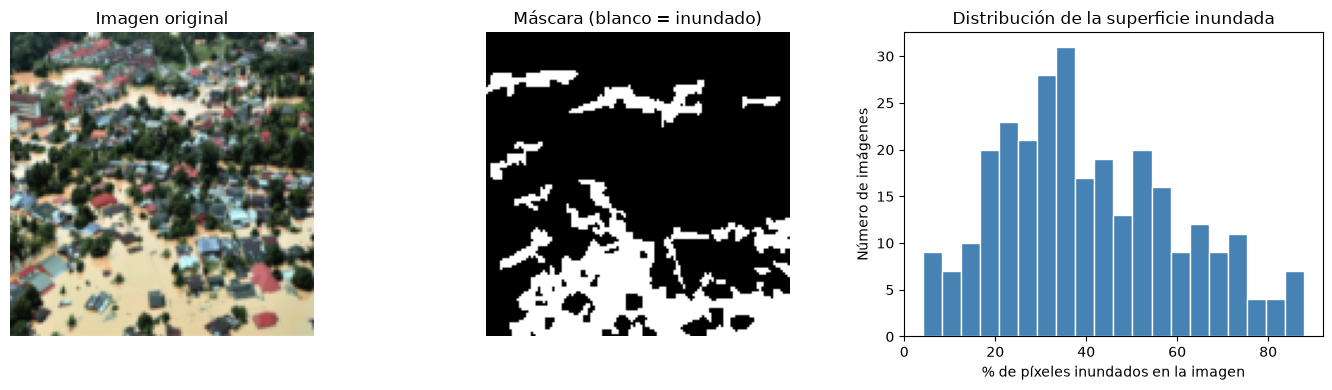

In [5]:
fraccion_agua = mascaras.float().mean(dim=(1, 2)).numpy()
print(f'Píxeles inundados en todo el dataset: {mascaras.float().mean().item():.1%}')
print(f'Fracción de agua por imagen: media {fraccion_agua.mean():.1%}, mínimo {fraccion_agua.min():.1%}, máximo {fraccion_agua.max():.1%}')

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(imagenes[0].permute(1, 2, 0))
axes[0].set_title('Imagen original')
axes[1].imshow(mascaras[0], cmap='gray')
axes[1].set_title('Máscara (blanco = inundado)')
for ax in axes[:2]:
    ax.axis('off')
axes[2].hist(fraccion_agua * 100, bins=20, color='steelblue', edgecolor='white')
axes[2].set_xlabel('% de píxeles inundados en la imagen')
axes[2].set_ylabel('Número de imágenes')
axes[2].set_title('Distribución de la superficie inundada')
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'exploracion_dataset.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. División en entrenamiento y test (punto 4 del enunciado)

80 % para entrenar y 20 % para test, con una permutación aleatoria con semilla fija para que sea reproducible. **Las imágenes de test no se usan para ninguna decisión** (ni para ajustar el learning rate ni para elegir época): solo para medir.

In [6]:
def dividir_indices(n, proporcion_test, semilla):
    generador = torch.Generator().manual_seed(semilla)
    permutacion = torch.randperm(n, generator=generador)
    n_test = int(round(n * proporcion_test))
    return permutacion[n_test:], permutacion[:n_test]


idx_train, idx_test = dividir_indices(len(nombres), CONFIG_BASE['proporcion_test'], CONFIG_BASE['semilla'])
print(f'Entrenamiento: {len(idx_train)} imágenes | Test: {len(idx_test)} imágenes')
print(f'% agua en entrenamiento: {mascaras[idx_train].float().mean().item():.1%} | en test: {mascaras[idx_test].float().mean().item():.1%}')

pd.DataFrame({'imagen': [nombres[i] for i in idx_test.tolist()]}).to_csv(RUTA_RESULTADOS / 'imagenes_test.csv', index=False)

Entrenamiento: 232 imágenes | Test: 58 imágenes
% agua en entrenamiento: 40.6% | en test: 40.5%


## 7. Data augmentation

Con solo ~230 imágenes de entrenamiento la red puede memorizarlas. El augmentation genera en **cada época** versiones distintas de cada imagen:

- Volteo horizontal y vertical (válido porque son fotos aéreas: no hay un "arriba" fijo).
- Rotación de hasta ±15°.
- Cambios de brillo, contraste, saturación y tono (simulan distintas condiciones de luz).

**Detalle clave en segmentación**: las transformaciones geométricas deben aplicarse **exactamente igual** a la imagen y a su máscara; si no, la etiqueta deja de corresponder con la foto. Envolviendo la máscara en `tv_tensors.Mask`, `v2.Compose` aplica el mismo volteo/rotación a ambas, usa vecino más cercano en la máscara y deja la máscara intacta en los cambios de color.

El augmentation se aplica **solo al entrenamiento**; el test se evalúa con las imágenes originales.

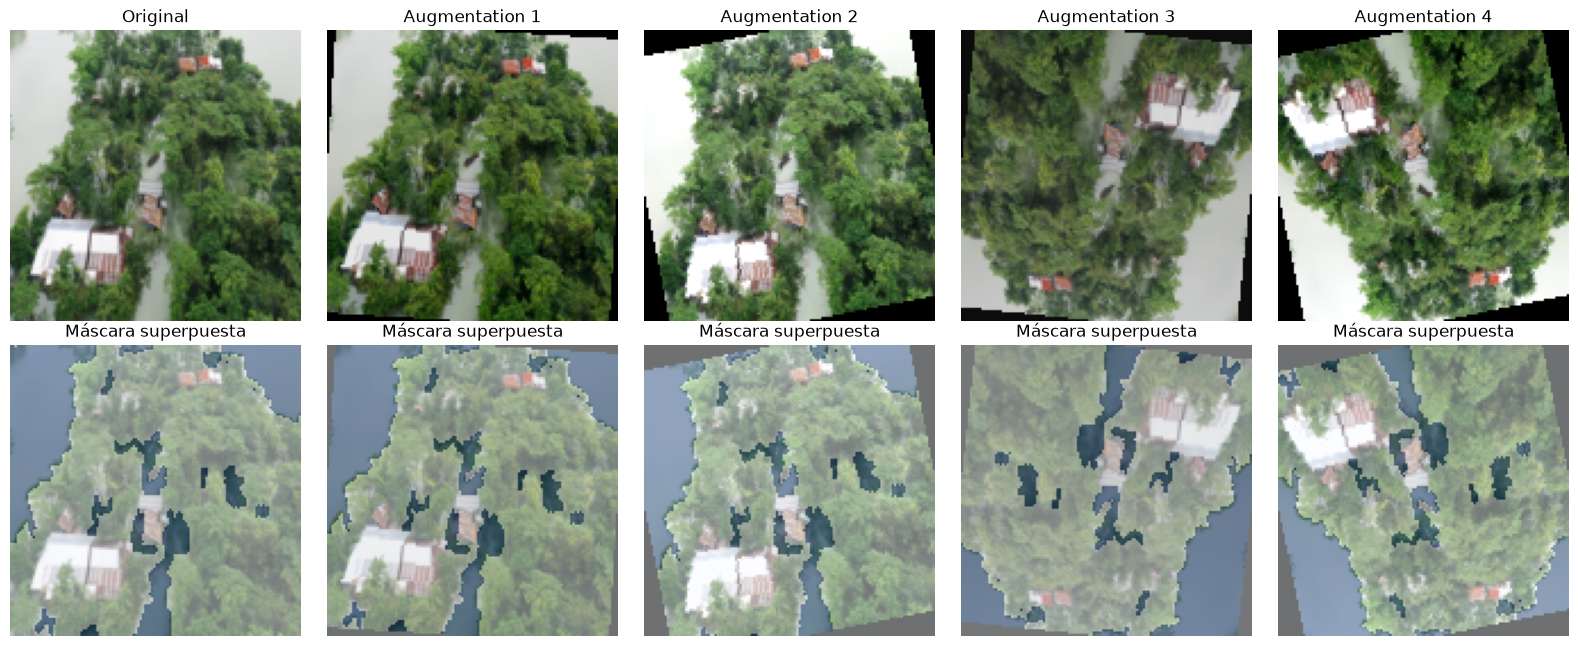

In [7]:
transform_augmentation = v2.Compose([
    v2.RandomHorizontalFlip(p=0.5),
    v2.RandomVerticalFlip(p=0.5),
    v2.RandomRotation(degrees=15),
    v2.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02),
])


class DatasetInundaciones(torch.utils.data.Dataset):
    # Devuelve pares (imagen, máscara) y aplica el augmentation al vuelo si se indica

    def __init__(self, imagenes, mascaras, transform=None):
        self.imagenes = imagenes
        self.mascaras = mascaras
        self.transform = transform

    def __len__(self):
        return len(self.imagenes)

    def __getitem__(self, i):
        imagen, mascara = self.imagenes[i], self.mascaras[i]
        if self.transform is not None:
            imagen, mascara = self.transform(tv_tensors.Image(imagen), tv_tensors.Mask(mascara))
        return imagen.as_subclass(torch.Tensor), mascara.as_subclass(torch.Tensor)


# Comprobación visual: la misma imagen con 4 augmentations; la máscara debe seguir encajando
fijar_semilla(CONFIG_BASE['semilla'])
ds_demo = DatasetInundaciones(imagenes[idx_train[:1]], mascaras[idx_train[:1]], transform_augmentation)
fig, axes = plt.subplots(2, 5, figsize=(16, 6.5))
muestras = [(imagenes[idx_train[0]], mascaras[idx_train[0]])] + [ds_demo[0] for _ in range(4)]
for col, (img, msk) in enumerate(muestras):
    axes[0, col].imshow(img.permute(1, 2, 0).clamp(0, 1))
    axes[0, col].set_title('Original' if col == 0 else f'Augmentation {col}')
    axes[1, col].imshow(img.permute(1, 2, 0).clamp(0, 1))
    axes[1, col].imshow(msk, alpha=0.45, cmap='Blues', vmin=0, vmax=1)
    axes[1, col].set_title('Máscara superpuesta')
    axes[0, col].axis('off')
    axes[1, col].axis('off')
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'ejemplos_augmentation.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Métricas

Se calculan acumulando píxeles sobre **todo el conjunto** (no promediando por lote), a partir de verdaderos/falsos positivos y negativos de la clase *inundado*:

- **IoU (Jaccard) inundación** = TP / (TP + FP + FN). Es la métrica que pide el enunciado.
- **IoU fondo** y **mIoU** (media de ambas clases).
- **Dice / F1** = 2·TP / (2·TP + FP + FN).
- **Exactitud por píxel** = (TP + TN) / total. Es la que en el `.py` original se llamaba "jaccard".
- **Pérdida**: entropía cruzada **media** por imagen (el original sumaba los lotes, lo que impide comparar conjuntos de distinto tamaño).

In [8]:
def metricas_desde_conteos(tp, fp, fn, tn, eps=1e-7):
    return {
        'iou_inundacion': tp / (tp + fp + fn + eps),
        'iou_fondo': tn / (tn + fn + fp + eps),
        'miou': 0.5 * (tp / (tp + fp + fn + eps) + tn / (tn + fn + fp + eps)),
        'dice': 2 * tp / (2 * tp + fp + fn + eps),
        'exactitud': (tp + tn) / (tp + fp + fn + tn + eps),
    }


def conteos(pred, target):
    tp = ((pred == 1) & (target == 1)).sum().item()
    fp = ((pred == 1) & (target == 0)).sum().item()
    fn = ((pred == 0) & (target == 1)).sum().item()
    tn = ((pred == 0) & (target == 0)).sum().item()
    return tp, fp, fn, tn


@torch.no_grad()
def evaluar(modelo, dataloader, criterio):
    modelo.eval()
    suma_loss, n = 0.0, 0
    tp = fp = fn = tn = 0
    for x, y in dataloader:
        x, y = x.to(device), y.to(device)
        logits = modelo(x)
        suma_loss += criterio(logits, y).item() * x.size(0)
        n += x.size(0)
        c = conteos(logits.argmax(dim=1), y)
        tp, fp, fn, tn = tp + c[0], fp + c[1], fn + c[2], tn + c[3]
    return {'loss': suma_loss / n, **metricas_desde_conteos(tp, fp, fn, tn)}


@torch.no_grad()
def predecir(modelo, imagenes_cpu, batch_size=16):
    modelo.eval()
    preds = [modelo(imagenes_cpu[i:i + batch_size].to(device)).argmax(dim=1).cpu()
             for i in range(0, len(imagenes_cpu), batch_size)]
    return torch.cat(preds)

## 9. Entrenamiento (puntos 5, 6 y 7 del enunciado)

El bucle es el del original, con estos cambios:

- `optimizer.zero_grad()` antes de cada retropropagación.
- Al final de cada época se evalúan **entrenamiento y test** en modo inferencia (`model.eval()`, sin gradientes y **sin augmentation**), así las dos curvas son comparables.
- Se guarda la predicción de una imagen fija de test en cada época para ver su evolución.
- Solo se guarda el modelo final (el original guardaba un checkpoint de ~120 MB por época).

La función `entrenar` recibe una configuración, lo que permite reutilizarla en la ablación.

In [9]:
def entrenar(config, nombre, indice_visual=None, verbose=True):
    fijar_semilla(config['semilla'])
    imgs, msks, _ = obtener_datos(config['tamanio_imagen'])

    transform = transform_augmentation if config['augmentation'] else None
    ds_train = DatasetInundaciones(imgs[idx_train], msks[idx_train], transform)
    ds_train_eval = DatasetInundaciones(imgs[idx_train], msks[idx_train], None)
    ds_test = DatasetInundaciones(imgs[idx_test], msks[idx_test], None)

    generador = torch.Generator().manual_seed(config['semilla'])
    dl_train = torch.utils.data.DataLoader(ds_train, batch_size=config['batch_size'], shuffle=True, generator=generador)
    dl_train_eval = torch.utils.data.DataLoader(ds_train_eval, batch_size=config['batch_size'])
    dl_test = torch.utils.data.DataLoader(ds_test, batch_size=config['batch_size'])

    modelo = UNet(n_channels=3, n_classes=2, bilinear=config['bilinear']).to(device)
    optimizer = torch.optim.Adam(modelo.parameters(), lr=config['learning_rate'])
    scheduler = StepLR(optimizer, step_size=config['step_size_scheduler'], gamma=config['gamma_scheduler'])
    criterio = torch.nn.CrossEntropyLoss()

    historial, evolucion = [], {}
    inicio = time.time()
    for epoch in range(1, config['epochs'] + 1):
        modelo.train()
        for x, y in dl_train:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterio(modelo(x), y)
            loss.backward()
            optimizer.step()

        m_train = evaluar(modelo, dl_train_eval, criterio)
        m_test = evaluar(modelo, dl_test, criterio)
        lr = optimizer.param_groups[0]['lr']
        historial.append({'epoch': epoch, 'lr': lr,
                          **{f'train_{k}': v for k, v in m_train.items()},
                          **{f'test_{k}': v for k, v in m_test.items()}})
        if verbose:
            print(f'[{nombre}] Época {epoch:02d}/{config["epochs"]} | lr={lr:.2e} | '
                  f'loss train={m_train["loss"]:.4f} test={m_test["loss"]:.4f} | '
                  f'IoU train={m_train["iou_inundacion"]:.4f} test={m_test["iou_inundacion"]:.4f}')

        if indice_visual is not None:
            evolucion[epoch] = predecir(modelo, imgs[indice_visual:indice_visual + 1])[0]

        scheduler.step()

    duracion = time.time() - inicio
    return modelo, pd.DataFrame(historial), evolucion, duracion

In [10]:
INDICE_VISUAL = int(idx_test[0])   # imagen de test fija para seguir su evolución

modelo, df_metricas, evolucion, duracion = entrenar(CONFIG_BASE, 'mejorado', indice_visual=INDICE_VISUAL)
print(f'\nTiempo de entrenamiento: {duracion / 60:.1f} min en {device}')

df_metricas.to_csv(RUTA_RESULTADOS / 'metricas_entrenamiento.csv', index=False)
torch.save({'model_state_dict': modelo.state_dict(), 'config': CONFIG_BASE},
           RUTA_MODELOS / 'unet_mejorado_final.pt')

[mejorado] Época 01/40 | lr=1.00e-03 | loss train=2.1182 test=2.1297 | IoU train=0.4063 test=0.4050
[mejorado] Época 02/40 | lr=1.00e-03 | loss train=1.3192 test=1.3277 | IoU train=0.4082 test=0.4060
[mejorado] Época 03/40 | lr=1.00e-03 | loss train=0.5703 test=0.5714 | IoU train=0.6079 test=0.6070
[mejorado] Época 04/40 | lr=1.00e-03 | loss train=0.3873 test=0.3979 | IoU train=0.6553 test=0.6538
[mejorado] Época 05/40 | lr=1.00e-03 | loss train=0.3678 test=0.4001 | IoU train=0.6660 test=0.6349
[mejorado] Época 06/40 | lr=1.00e-03 | loss train=0.3843 test=0.3912 | IoU train=0.6396 test=0.6426
[mejorado] Época 07/40 | lr=1.00e-03 | loss train=0.4013 test=0.4147 | IoU train=0.6033 test=0.6042
[mejorado] Época 08/40 | lr=1.00e-03 | loss train=0.4019 test=0.4093 | IoU train=0.6686 test=0.6563
[mejorado] Época 09/40 | lr=1.00e-03 | loss train=0.3746 test=0.3783 | IoU train=0.6784 test=0.6708
[mejorado] Época 10/40 | lr=1.00e-03 | loss train=0.3566 test=0.3707 | IoU train=0.6874 test=0.6699


## 10. Curvas de pérdida e IoU en entrenamiento y test (apartados b y c de la entrega)

Si las dos curvas bajan (pérdida) o suben (IoU) juntas, el modelo generaliza. Si la de entrenamiento sigue mejorando mientras la de test se estanca o empeora, hay sobreajuste.

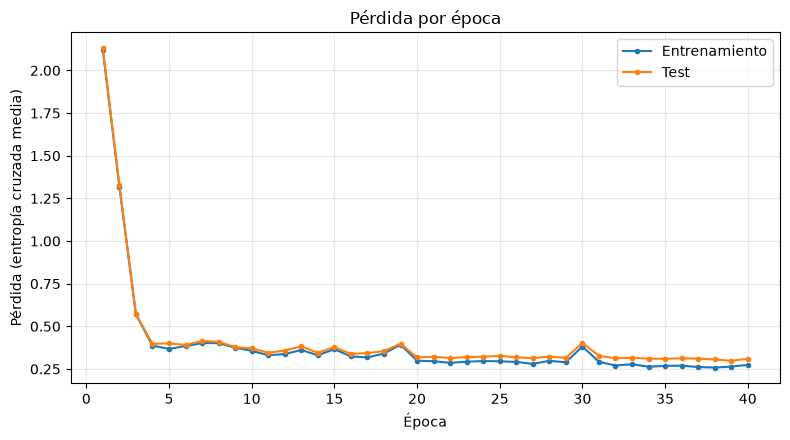

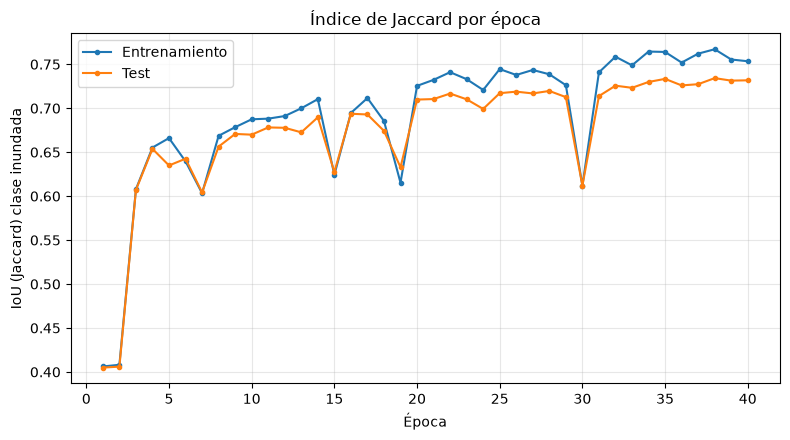

In [11]:
def guardar_curva(df, columna, etiqueta_y, titulo, archivo):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(df['epoch'], df[f'train_{columna}'], marker='o', markersize=3, label='Entrenamiento')
    ax.plot(df['epoch'], df[f'test_{columna}'], marker='o', markersize=3, label='Test')
    ax.set_xlabel('Época')
    ax.set_ylabel(etiqueta_y)
    ax.set_title(titulo)
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / archivo, dpi=150, bbox_inches='tight')
    plt.show()


guardar_curva(df_metricas, 'loss', 'Pérdida (entropía cruzada media)', 'Pérdida por época', 'curva_perdida_train_test.png')
guardar_curva(df_metricas, 'iou_inundacion', 'IoU (Jaccard) clase inundada', 'Índice de Jaccard por época', 'curva_iou_train_test.png')

In [12]:
# Métricas finales (última época)
final = df_metricas.iloc[-1]
tabla_final = pd.DataFrame({
    'Entrenamiento': [final[f'train_{m}'] for m in ['loss', 'iou_inundacion', 'iou_fondo', 'miou', 'dice', 'exactitud']],
    'Test': [final[f'test_{m}'] for m in ['loss', 'iou_inundacion', 'iou_fondo', 'miou', 'dice', 'exactitud']],
}, index=['Pérdida', 'IoU inundación', 'IoU fondo', 'mIoU', 'Dice', 'Exactitud por píxel']).round(4)
tabla_final.to_csv(RUTA_RESULTADOS / 'metricas_finales.csv')
tabla_final

,Entrenamiento,Test
Pérdida,0.2740,0.3101
IoU inundación,0.7535,0.7318
IoU fondo,0.8260,0.8125
mIoU,0.7897,0.7721
Dice,0.8594,0.8451
Exactitud por píxel,0.8864,0.8759


## 11. Evolución de la predicción durante el entrenamiento

La misma imagen de test vista en distintas épocas: al principio la máscara predicha es casi ruido y va convergiendo hacia la máscara real.

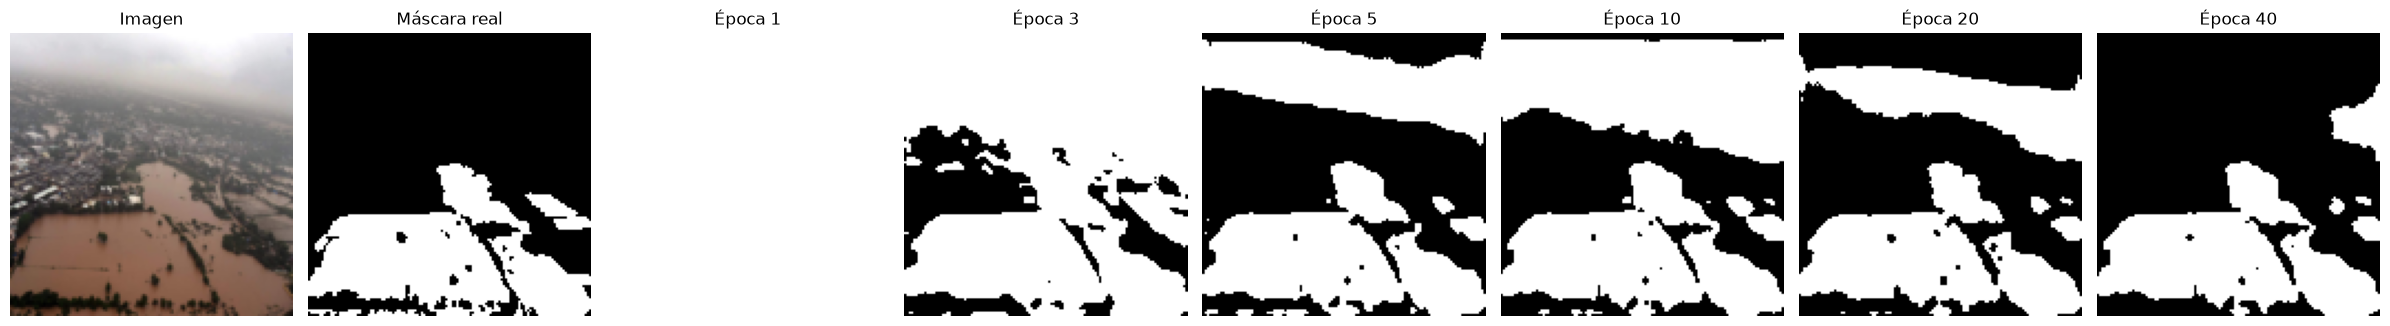

In [13]:
epocas_mostrar = sorted({e for e in [1, 3, 5, 10, 20, CONFIG_BASE['epochs']] if e in evolucion})
img_vis = imagenes[INDICE_VISUAL].permute(1, 2, 0)

fig, axes = plt.subplots(1, len(epocas_mostrar) + 2, figsize=(3 * (len(epocas_mostrar) + 2), 3.4))
axes[0].imshow(img_vis)
axes[0].set_title('Imagen')
axes[1].imshow(mascaras[INDICE_VISUAL], cmap='gray', vmin=0, vmax=1)
axes[1].set_title('Máscara real')
for ax, e in zip(axes[2:], epocas_mostrar):
    ax.imshow(evolucion[e], cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'Época {e}')
for ax in axes:
    ax.axis('off')
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'evolucion_prediccion.png', dpi=150, bbox_inches='tight')
plt.show()

## 12. Análisis de errores en test

IoU de cada imagen de test por separado. Se muestran las 3 mejores y las 3 peores para ver en qué situaciones falla el modelo (en clase se observó que confundía el cielo o el horizonte con agua).

IoU por imagen en test: media 0.681, mediana 0.761, mínimo 0.004, máximo 0.937


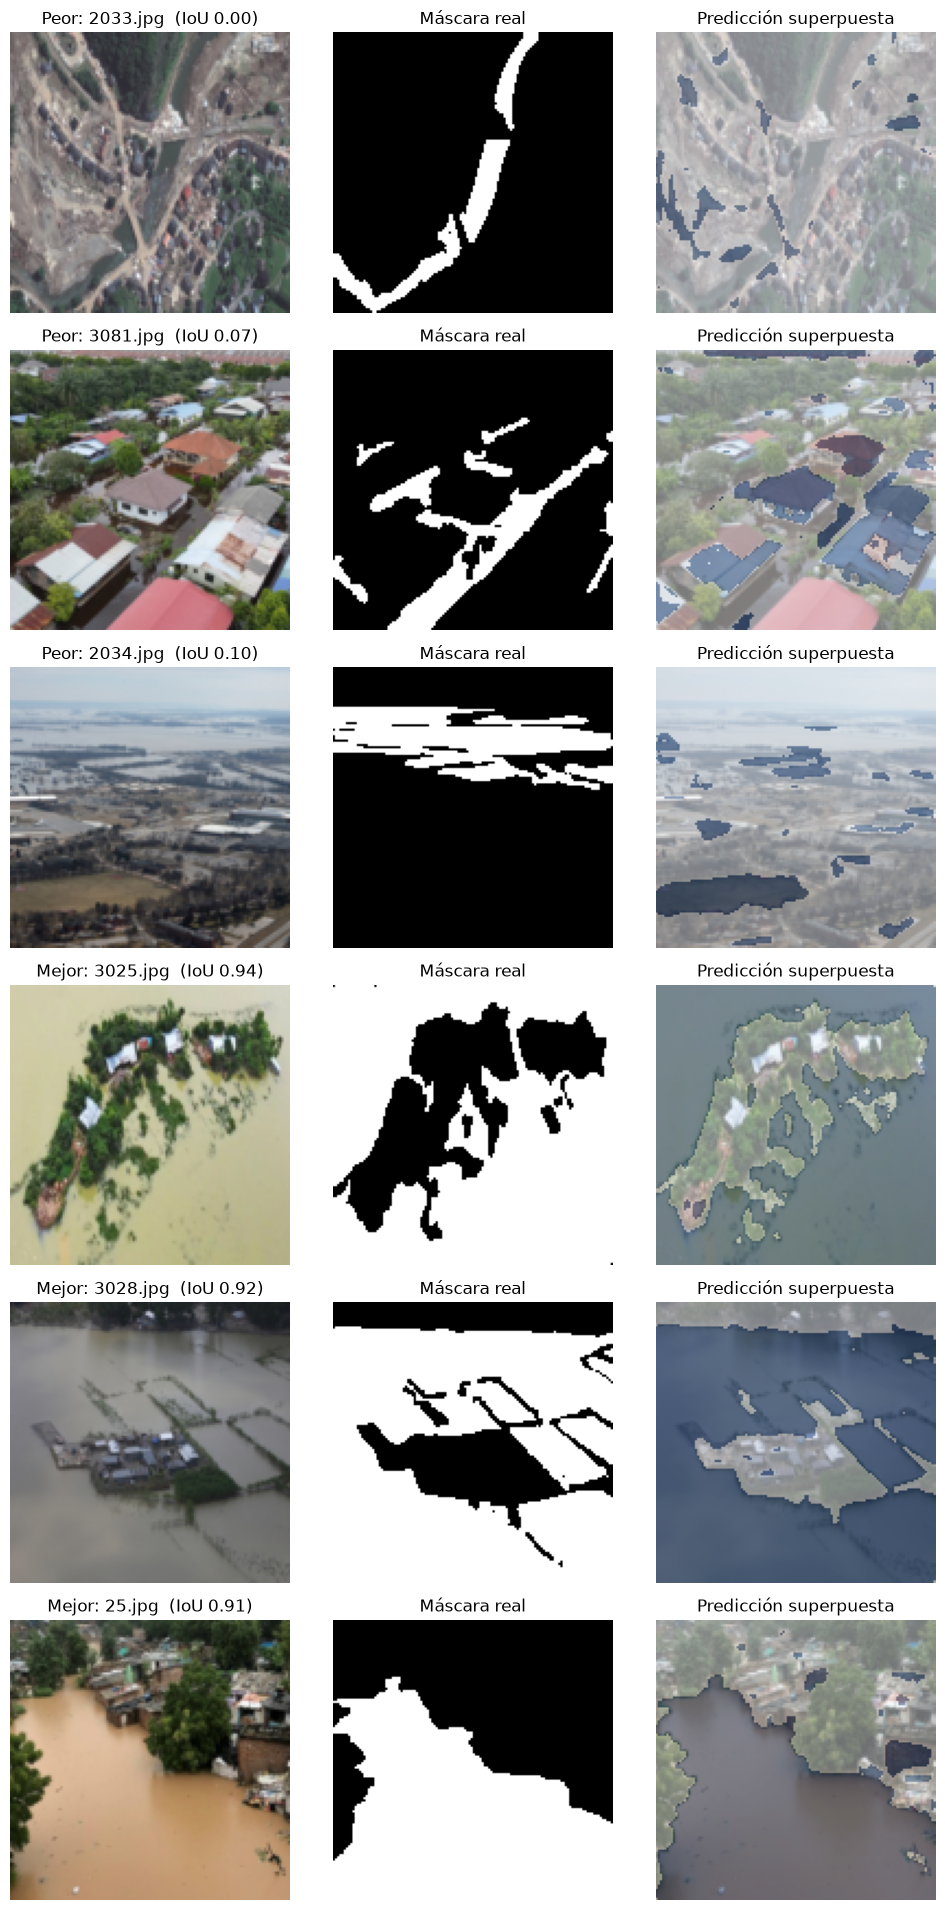

In [14]:
preds_test = predecir(modelo, imagenes[idx_test])
masks_test = mascaras[idx_test]

iou_por_imagen = []
for p, t in zip(preds_test, masks_test):
    inter = ((p == 1) & (t == 1)).sum().item()
    union = ((p == 1) | (t == 1)).sum().item()
    iou_por_imagen.append(1.0 if union == 0 else inter / union)
iou_por_imagen = np.array(iou_por_imagen)

df_iou_img = pd.DataFrame({'imagen': [nombres[i] for i in idx_test.tolist()], 'iou': iou_por_imagen}).sort_values('iou')
df_iou_img.to_csv(RUTA_RESULTADOS / 'iou_por_imagen_test.csv', index=False)
print(f'IoU por imagen en test: media {iou_por_imagen.mean():.3f}, mediana {np.median(iou_por_imagen):.3f}, '
      f'mínimo {iou_por_imagen.min():.3f}, máximo {iou_por_imagen.max():.3f}')

orden = np.argsort(iou_por_imagen)
seleccion = [('Peor', i) for i in orden[:3]] + [('Mejor', i) for i in orden[::-1][:3]]

fig, axes = plt.subplots(len(seleccion), 3, figsize=(10, 3.2 * len(seleccion)))
for fila, (tipo, i) in enumerate(seleccion):
    img = imagenes[idx_test[i]].permute(1, 2, 0)
    axes[fila, 0].imshow(img)
    axes[fila, 0].set_title(f'{tipo}: {nombres[idx_test[i]]}  (IoU {iou_por_imagen[i]:.2f})')
    axes[fila, 1].imshow(masks_test[i], cmap='gray', vmin=0, vmax=1)
    axes[fila, 1].set_title('Máscara real')
    axes[fila, 2].imshow(img)
    axes[fila, 2].imshow(preds_test[i], alpha=0.45, cmap='Blues', vmin=0, vmax=1)
    axes[fila, 2].set_title('Predicción superpuesta')
    for ax in axes[fila]:
        ax.axis('off')
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'mejores_peores_test.png', dpi=130, bbox_inches='tight')
plt.show()

## 13. Comparación con métodos clásicos: K-means y Chan-Vese

Los métodos de la unidad 3 que no usan redes neuronales, aplicados a las mismas imágenes de test:

- **K-means** con K = 2 sobre los colores RGB de cada imagen (agua / no agua).
- **Chan-Vese** sobre la imagen en escala de grises (minimiza una función de energía para ajustar un contorno).

Ninguno de los dos sabe cuál de sus dos grupos es el agua. Para no penalizarlos se elige, en cada imagen, la asignación que mejor encaja con la máscara real. Es una ventaja que la U-Net no tiene, así que el resultado de los métodos clásicos es **optimista**.

Métodos clásicos calculados en 5 s


,IoU inundación,mIoU,Dice,Exactitud
K-means (K=2),0.5658,0.5873,0.7227,0.7409
Chan-Vese,0.5372,0.5690,0.6990,0.7272
U-Net mejorada,0.7318,0.7721,0.8451,0.8759


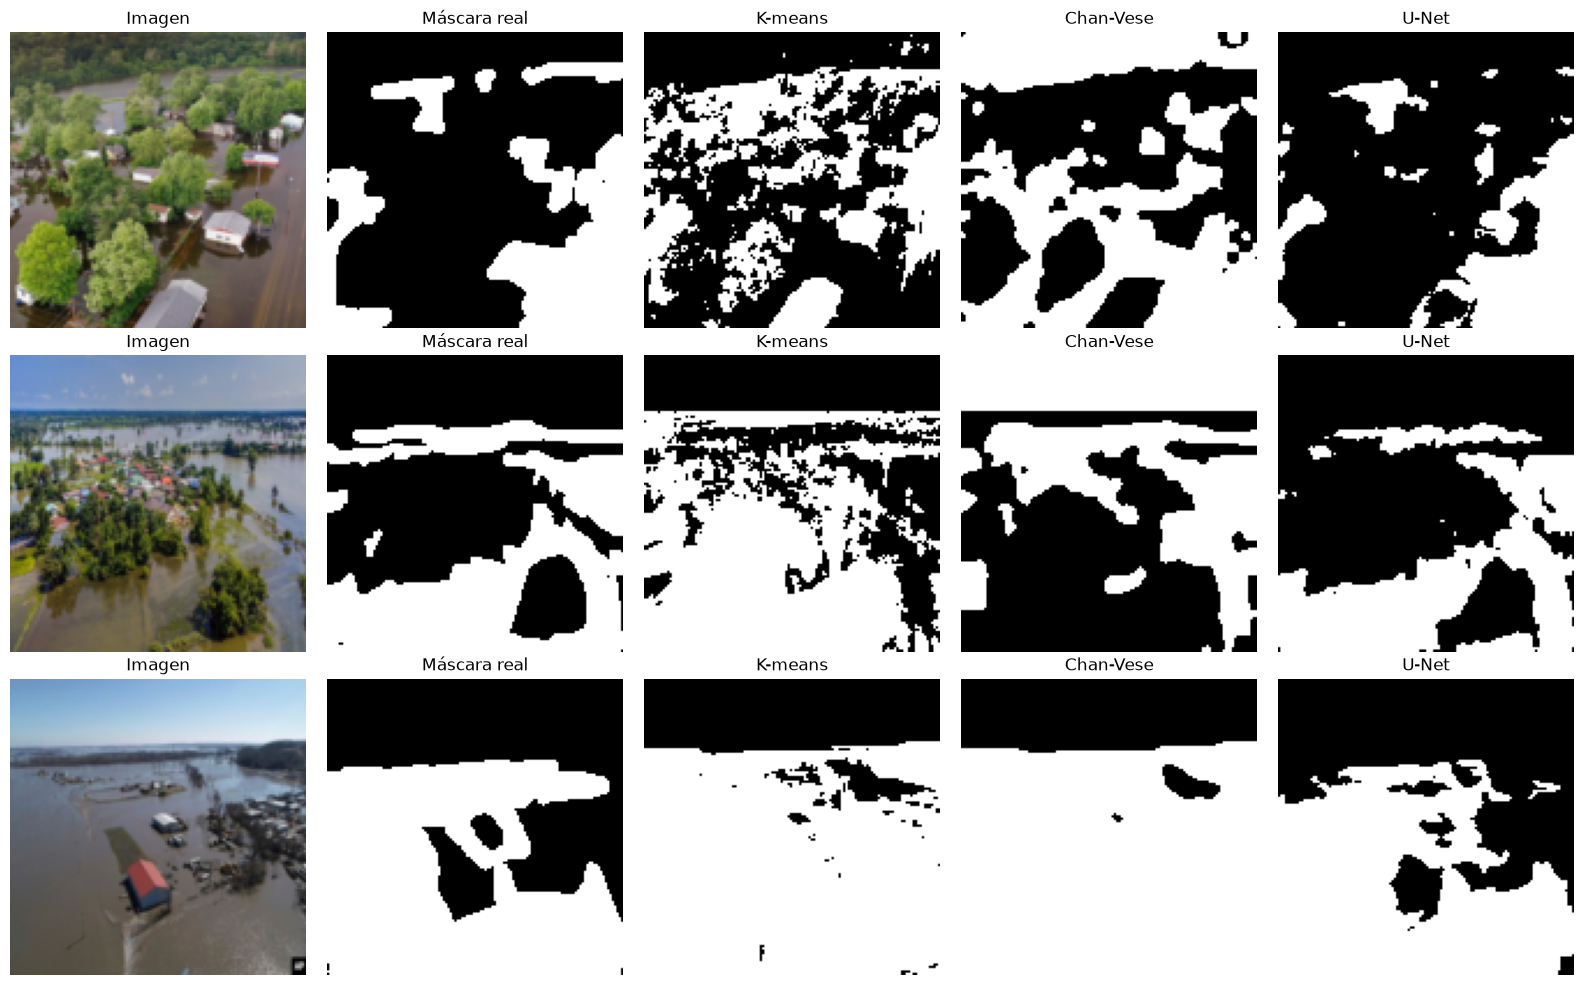

In [15]:
def elegir_polaridad(segmentacion_bool, mascara_real):
    # Devuelve la segmentación o su inversa, la que más IoU tenga con la máscara real
    def iou(a, b):
        u = (a | b).sum()
        return 1.0 if u == 0 else (a & b).sum() / u
    inversa = ~segmentacion_bool
    return segmentacion_bool if iou(segmentacion_bool, mascara_real) >= iou(inversa, mascara_real) else inversa


if EJECUTAR_METODOS_CLASICOS:
    inicio = time.time()
    preds_kmeans, preds_chanvese = [], []
    for i in idx_test.tolist():
        img = imagenes[i].permute(1, 2, 0).numpy()
        real = mascaras[i].numpy().astype(bool)
        h, w, _ = img.shape

        etiquetas = KMeans(n_clusters=2, n_init=5, random_state=CONFIG_BASE['semilla']).fit_predict(img.reshape(-1, 3))
        preds_kmeans.append(elegir_polaridad(etiquetas.reshape(h, w).astype(bool), real))

        cv = chan_vese(rgb2gray(img), mu=0.25, lambda1=1, lambda2=1, tol=1e-3, max_num_iter=200, dt=0.5)
        preds_chanvese.append(elegir_polaridad(cv.astype(bool), real))
    print(f'Métodos clásicos calculados en {time.time() - inicio:.0f} s')

    resultados_metodos = {}
    for nombre_metodo, preds in [('K-means (K=2)', torch.tensor(np.stack(preds_kmeans)).long()),
                                 ('Chan-Vese', torch.tensor(np.stack(preds_chanvese)).long()),
                                 ('U-Net mejorada', preds_test)]:
        resultados_metodos[nombre_metodo] = metricas_desde_conteos(*conteos(preds, masks_test))

    tabla_metodos = pd.DataFrame(resultados_metodos).T[['iou_inundacion', 'miou', 'dice', 'exactitud']].round(4)
    tabla_metodos.columns = ['IoU inundación', 'mIoU', 'Dice', 'Exactitud']
    tabla_metodos.to_csv(RUTA_RESULTADOS / 'comparacion_metodos_clasicos.csv')
    display(tabla_metodos)

    ejemplos = orden[[len(orden) // 4, len(orden) // 2, 3 * len(orden) // 4]]
    fig, axes = plt.subplots(len(ejemplos), 5, figsize=(16, 3.3 * len(ejemplos)))
    for fila, i in enumerate(ejemplos):
        paneles = [(imagenes[idx_test[i]].permute(1, 2, 0), 'Imagen', None),
                   (masks_test[i], 'Máscara real', 'gray'),
                   (preds_kmeans[i], 'K-means', 'gray'),
                   (preds_chanvese[i], 'Chan-Vese', 'gray'),
                   (preds_test[i], 'U-Net', 'gray')]
        for col, (dato, titulo, cmap) in enumerate(paneles):
            axes[fila, col].imshow(dato, cmap=cmap)
            axes[fila, col].set_title(titulo)
            axes[fila, col].axis('off')
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'comparacion_metodos_clasicos.png', dpi=130, bbox_inches='tight')
    plt.show()

## 14. Ablación: qué aporta cada mejora

Se entrenan variantes cambiando **una cosa cada vez**, todas con la misma división train/test y las mismas métricas:

| Experimento | Descripción |
|---|---|
| A — Original | Hiperparámetros del notebook original: 100×100, lr 0.01 dividido entre 2 cada época, 20 épocas, sin augmentation |
| B — + Scheduler | A con lr 0.001, reducción cada 10 épocas, 40 épocas |
| C — + Augmentation | B con data augmentation |
| D — + 128×128 | C con resolución 128 (= modelo mejorado de las secciones anteriores; no se reentrena) |
| E — Bilinear | D usando interpolación bilineal en lugar de convolución transpuesta |

El experimento A permite comparar honestamente con el original: el 0,65 de IoU del original se medía sobre las mismas imágenes con las que entrenaba.

El tiempo total es aproximadamente 4 veces el del entrenamiento principal.

A - Original: IoU test 0.6388 | IoU train 0.6522 | 0.7 min
B - + Scheduler: IoU test 0.7395 | IoU train 0.8035 | 1.4 min
C - + Augmentation: IoU test 0.7233 | IoU train 0.7611 | 1.5 min
E - Bilinear: IoU test 0.7129 | IoU train 0.7540 | 1.9 min


,IoU train,IoU test,mIoU test,Dice test,Pérdida test,Diferencia IoU train-test,Minutos
Experimento,,,,,,,
A - Original,0.6522,0.6388,0.7029,0.7796,0.3845,0.0134,0.7176
B - + Scheduler,0.8035,0.7395,0.7798,0.8503,0.3039,0.0639,1.4045
C - + Augmentation,0.7611,0.7233,0.7637,0.8395,0.3198,0.0378,1.4606
D - + 128x128 (mejorado),0.7535,0.7318,0.7721,0.8451,0.3101,0.0217,2.2891
E - Bilinear,0.7540,0.7129,0.7560,0.8324,0.3397,0.0412,1.9188


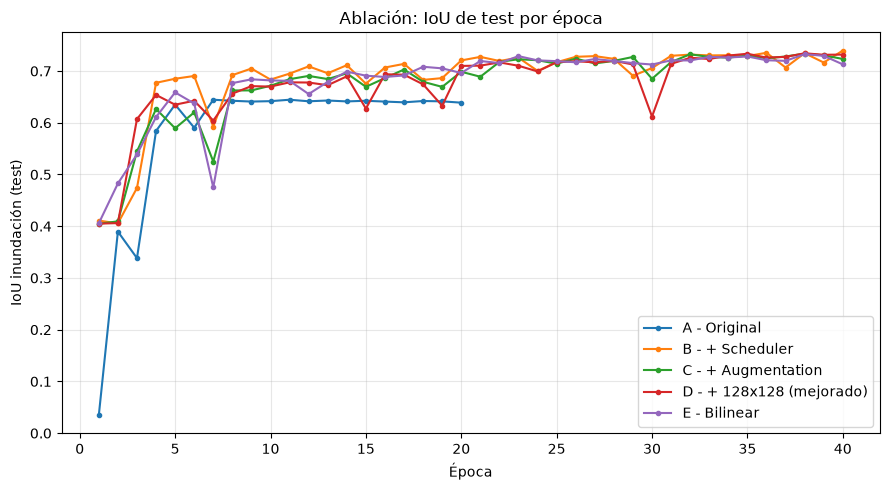

In [16]:
if EJECUTAR_ABLACION:
    EXPERIMENTOS = {
        'A - Original': {**CONFIG_BASE, 'tamanio_imagen': 100, 'epochs': 20, 'learning_rate': 0.01,
                         'step_size_scheduler': 1, 'gamma_scheduler': 0.5, 'augmentation': False},
        'B - + Scheduler': {**CONFIG_BASE, 'tamanio_imagen': 100, 'augmentation': False},
        'C - + Augmentation': {**CONFIG_BASE, 'tamanio_imagen': 100},
        'E - Bilinear': {**CONFIG_BASE, 'bilinear': True},
    }

    resultados_ablacion = {'D - + 128x128 (mejorado)': (df_metricas, duracion)}
    for nombre_exp, cfg in EXPERIMENTOS.items():
        _, df_exp, _, dur_exp = entrenar(cfg, nombre_exp, verbose=False)
        resultados_ablacion[nombre_exp] = (df_exp, dur_exp)
        ult = df_exp.iloc[-1]
        print(f'{nombre_exp}: IoU test {ult["test_iou_inundacion"]:.4f} | IoU train {ult["train_iou_inundacion"]:.4f} | {dur_exp / 60:.1f} min')

    orden_exp = ['A - Original', 'B - + Scheduler', 'C - + Augmentation', 'D - + 128x128 (mejorado)', 'E - Bilinear']
    filas = []
    for nombre_exp in orden_exp:
        df_exp, dur_exp = resultados_ablacion[nombre_exp]
        ult = df_exp.iloc[-1]
        filas.append({'Experimento': nombre_exp,
                      'IoU train': ult['train_iou_inundacion'],
                      'IoU test': ult['test_iou_inundacion'],
                      'mIoU test': ult['test_miou'],
                      'Dice test': ult['test_dice'],
                      'Pérdida test': ult['test_loss'],
                      'Diferencia IoU train-test': ult['train_iou_inundacion'] - ult['test_iou_inundacion'],
                      'Minutos': dur_exp / 60})
    tabla_ablacion = pd.DataFrame(filas).set_index('Experimento').round(4)
    tabla_ablacion.to_csv(RUTA_RESULTADOS / 'ablacion.csv')
    pd.concat({n: resultados_ablacion[n][0] for n in orden_exp}, names=['experimento']).to_csv(
        RUTA_RESULTADOS / 'ablacion_historial.csv')
    display(tabla_ablacion)

    fig, ax = plt.subplots(figsize=(9, 5))
    for nombre_exp in orden_exp:
        df_exp = resultados_ablacion[nombre_exp][0]
        ax.plot(df_exp['epoch'], df_exp['test_iou_inundacion'], marker='o', markersize=3, label=nombre_exp)
    ax.set_xlabel('Época')
    ax.set_ylabel('IoU inundación (test)')
    ax.set_title('Ablación: IoU de test por época')
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'ablacion_iou_test.png', dpi=150, bbox_inches='tight')
    plt.show()

## 15. Archivos generados

En `resultados_unet_mejorado/`:

- `configuracion.json`: parámetros del modelo mejorado.
- `imagenes_test.csv`: qué imágenes forman el conjunto de test.
- `metricas_entrenamiento.csv`: pérdida y métricas de entrenamiento y test por época.
- `metricas_finales.csv`, `iou_por_imagen_test.csv`, `comparacion_metodos_clasicos.csv`, `ablacion.csv`, `ablacion_historial.csv`.
- `modelos/unet_mejorado_final.pt`: pesos del modelo final.
- `figuras/`: todas las figuras en PNG, listas para el PDF:
  `exploracion_dataset`, `ejemplos_augmentation`, `curva_perdida_train_test`, `curva_iou_train_test`, `evolucion_prediccion`, `mejores_peores_test`, `comparacion_metodos_clasicos`, `ablacion_iou_test`.